# Do Combine movement traits improve edge-rusher predictions?

**Question:** do burst and bend measurements add predictive value beyond traditional Combine tests for rookie NFL recorded-pressure rate?

This is an exploratory comparison, not a claim that tracking must win. All models use the same players and held-out draft classes. The independent sample size is the number of **players**, not the number of plays.

**Run:** install `requirements-notebook.txt` into the project `.venv`, select that Python kernel, and run all cells. The notebook finds the local `data/nfl-big-data-bowl-2027` directory from the repository root or the `notebooks` directory. No downloads or multi-gigabyte NFL tracking reads are needed.

**Interpretation limit:** the local CSVs contain no data dictionary confirming missing pressure-label semantics or physical tracking units. We audit an explicit opportunity proxy and predict **recorded** pressures. Claims about true pressure probability remain blocked pending documentation or film validation. Movement measurements describe trajectories, not body lean, ankle flexibility, contact technique, or causal development effects.

In [1]:
from pathlib import Path
import sys
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11})
pd.set_option("display.max_columns", 24)
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/nfl-big-data-bowl-2027/players.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or notebooks directory; local data is required.")
DATA = ROOT / "data/nfl-big-data-bowl-2027"
SEED = 2027
MIN_OPPORTUNITIES = 25
BOOTSTRAPS = 2000
TRADITIONAL = ["combine_height", "combine_weight", "forty", "ten_yd_split",
               "three_cone", "short_shuttle", "vertical", "broad_jump"]
BURST = ["burst_speed_gain_1s", "burst_distance_1s"]
BEND = ["bend_speed_retention", "bend_turn_radius"]
MOVEMENT = BURST + BEND
DRILLS = ["PASS_RUSH_DRILL", "RUN_THE_HOOP_DRILL"]
ATTEMPT_KEY = ["nfl_id", "draft_year", "drill_type", "drill_name", "event_id", "attempt"]
print("Python", platform.python_version(), "| data:", DATA)
display(pd.Series({p: importlib.metadata.version(p) for p in
                   ["numpy", "pandas", "matplotlib", "scikit-learn", "scipy", "nbclient"]},
                  name="Executed with"))

Matplotlib is building the font cache; this may take a moment.


Python 3.14.2 | data: /Users/waidyn/Projects/big-data-bowl-2027/data/nfl-big-data-bowl-2027


numpy            2.5.3
pandas           3.0.6
matplotlib      3.11.2
scikit-learn     1.9.1
scipy           1.18.1
nbclient        0.11.0
Name: Executed with, dtype: str

## 1. Cohort and outcome audit

Start with roster positions DE/OLB, then measure only their rookie regular-season EDGE appearances. This excludes occasional edge-aligned defensive backs and does not treat every OLB snap as a pass rush. It can omit some true edge rushers classified elsewhere; the cohort is a practical starting definition, not a universal position taxonomy.

An **eligible opportunity proxy** must be defensive, have a recorded pass result (`C`, `I`, `IN`, `S`, or `R`, including sacks/scrambles), have `NO_ASSIGNMENT` coverage, have populated sack information, and not be nullified by penalty. Unknown coverage or sack information is excluded, not converted to a negative outcome. `blitzing` and get-off are audited but are not used as mandatory filters.

Within that proxy, `recorded_pressure = time_to_pressure.notna()`. A zero means **no recorded pressure time**, not a verified failed rush. Sacks, quick-pressure flags, and unblocked-pressure flags are consistency checks. Players without eligible opportunities have an unknown outcome, not a zero success rate.

In [2]:
players = pd.read_csv(DATA / "players.csv")
combine = pd.read_csv(DATA / "combine_results.csv")
games = pd.read_csv(DATA / "games.csv")
PLAY_COLUMNS = ["game_id", "play_id", "nfl_id", "team_abbr", "possession_team",
                "lined_up_position", "pass_result", "play_nullified_by_penalty",
                "coverage_assignment", "sack", "time_to_pressure", "quick_pressure",
                "unblocked_pressure", "player_get_off", "blitzing", "dropback_duration"]
player_play = pd.read_csv(DATA / "player_play.csv", usecols=PLAY_COLUMNS, low_memory=False)
assert not players.duplicated("nfl_id").any()
assert not combine.duplicated(["nfl_id", "draft_year"]).any()
assert not games.duplicated("game_id").any()
assert not player_play.duplicated(["game_id", "play_id", "nfl_id"]).any()
prospects = players.loc[players.nfl_position.isin(["DE", "OLB"])].copy()
plays = (player_play.merge(prospects[["nfl_id", "draft_year"]], on="nfl_id", validate="many_to_one")
         .merge(games[["game_id", "season", "season_type"]], on="game_id",
                how="left", validate="many_to_one", indicator=True))
assert plays["_merge"].eq("both").all(), "Unmatched game metadata"
plays = plays.drop(columns="_merge")
assert set(plays.pass_result.dropna().unique()) <= {"C", "I", "IN", "S", "R"}

stages = []
def record_stage(label, frame):
    for year in sorted(prospects.draft_year.unique()):
        z = frame.loc[frame.draft_year.eq(year)]
        stages.append({"stage": label, "draft_year": year,
                       "players": z.nfl_id.nunique(), "rows": len(z)})
record_stage("DE/OLB with supplied plays", plays)
rookie = plays.loc[plays.season_type.eq("REG") & plays.season.eq(plays.draft_year)].copy()
record_stage("Rookie regular season", rookie)
edge = rookie.loc[rookie.lined_up_position.eq("EDGE") &
                  rookie.team_abbr.ne(rookie.possession_team)].copy()
record_stage("Defensive EDGE", edge)
dropbacks = edge.loc[edge.pass_result.notna() & edge.play_nullified_by_penalty.eq("N")].copy()
record_stage("Recorded dropback, not nullified", dropbacks)
opportunities = dropbacks.loc[dropbacks.coverage_assignment.eq("NO_ASSIGNMENT") &
                               dropbacks.sack.notna()].copy()
opportunities["recorded_pressure"] = opportunities.time_to_pressure.notna().astype(int)
record_stage("Eligible opportunity proxy", opportunities)
display(pd.DataFrame(stages).set_index(["stage", "draft_year"]))

label_columns = ["time_to_pressure", "quick_pressure", "sack", "unblocked_pressure",
                 "player_get_off", "blitzing", "coverage_assignment"]
missingness = pd.concat({"EDGE dropbacks": dropbacks[label_columns].isna().mean(),
                         "Eligible proxy": opportunities[label_columns].isna().mean()}, axis=1)
display(missingness.mul(100).round(1).rename_axis("Percent missing"))
display(pd.crosstab(dropbacks.coverage_assignment.fillna("MISSING"),
                    dropbacks.sack.notna(), colnames=["Sack field populated"]))

players   rows
stage                            draft_year                
DE/OLB with supplied plays       2023             25  26734
                                 2024             18  12423
                                 2025             20   5771
Rookie regular season            2023             21   5637
                                 2024             16   4591
                                 2025             17   4337
Defensive EDGE                   2023             21   4560
                                 2024             16   3831
                                 2025             17   3429
Recorded dropback, not nullified 2023             21   2567
                                 2024             16   2169
                                 2025             17   1830
Eligible opportunity proxy       2023             21   2312
                                 2024             16   2023
                                 2025             17   1602

,EDGE dropbacks,Eligible proxy
Percent missing,,
time_to_pressure,89.9,88.8
quick_pressure,89.9,88.9
sack,0.9,0.0
unblocked_pressure,0.9,0.0
player_get_off,11.7,4.0
blitzing,0.8,0.0
coverage_assignment,0.6,0.0


Sack field populated,False,True
coverage_assignment,,
CURL_FLAT_LEFT,0,118
CURL_FLAT_RIGHT,1,140
FLAT_LEFT,0,9
FLAT_RIGHT,0,13
HOLE,15,79
HOOK_CURL_LEFT,0,96
HOOK_CURL_RIGHT,0,83
MAN,0,33
MISSING,39,0


In [3]:
has_pressure = opportunities.time_to_pressure.notna()
audit = pd.Series({
    "Eligible opportunities": len(opportunities),
    "Recorded pressures": int(has_pressure.sum()),
    "Sack without recorded pressure": int((opportunities.sack.gt(0) & ~has_pressure).sum()),
    "Populated quick-pressure flag without recorded pressure": int((opportunities.quick_pressure.notna() & ~has_pressure).sum()),
    "Unblocked-pressure flag true without recorded pressure": int((opportunities.unblocked_pressure.eq(True) & ~has_pressure).sum()),
    "Recorded pressure without quick-pressure flag": int((has_pressure & opportunities.quick_pressure.isna()).sum()),
    "Nonpositive or nonfinite recorded pressure time": int((has_pressure &
        (~np.isfinite(opportunities.time_to_pressure) | opportunities.time_to_pressure.le(0))).sum()),
    "Missing unblocked-pressure field": int(opportunities.unblocked_pressure.isna().sum()),
}, name="Count")
display(audit)
critical_checks = ["Sack without recorded pressure",
                   "Populated quick-pressure flag without recorded pressure",
                   "Unblocked-pressure flag true without recorded pressure",
                   "Nonpositive or nonfinite recorded pressure time"]
PROXY_AUDIT_PASSED = len(opportunities) > 0 and audit[critical_checks].eq(0).all()
# The CSVs do not independently verify missing-label or opportunity semantics.
TRUE_PRESSURE_CONCLUSIONS_ALLOWED = False
if PROXY_AUDIT_PASSED:
    display(Markdown("**Audit: suitable for an exploratory recorded-label comparison.** "
                     "This does not validate the proxy as an exhaustive set of pass rushes. "
                     "True pressure-rate conclusions remain blocked."))
else:
    display(Markdown("**Modeling blocked:** the opportunity/label proxy failed its consistency audit. "
                     "The movement exploration still runs; resolve the flagged records before fitting models."))

outcomes = (opportunities.groupby(["nfl_id", "draft_year"], as_index=False)
            .agg(opportunities=("recorded_pressure", "size"),
                 recorded_pressures=("recorded_pressure", "sum"),
                 sack_credits=("sack", "sum"),
                 recorded_quick_pressures=("quick_pressure", lambda s: s.eq(True).sum()),
                 recorded_unblocked_pressures=("unblocked_pressure", lambda s: s.eq(True).sum())))
outcomes["recorded_pressure_rate"] = outcomes.recorded_pressures / outcomes.opportunities
outcomes["sack_credit_rate"] = outcomes.sack_credits / outcomes.opportunities
outcomes["recorded_quick_pressure_rate"] = outcomes.recorded_quick_pressures / outcomes.opportunities
assert outcomes.recorded_pressures.between(0, outcomes.opportunities).all()
assert outcomes.recorded_pressure_rate.between(0, 1).all()
cohort = (prospects.merge(combine, on=["nfl_id", "draft_year"], how="left", validate="one_to_one")
          .merge(outcomes, on=["nfl_id", "draft_year"], how="left", validate="one_to_one"))
cohort["has_25_opportunities"] = cohort.opportunities.ge(MIN_OPPORTUNITIES)
display(cohort.groupby("draft_year").agg(
    DE_OLB_prospects=("nfl_id", "size"), with_eligible_opportunities=("opportunities", "count"),
    with_25_opportunities=("has_25_opportunities", "sum")))
display(cohort.groupby("draft_year")[TRADITIONAL].count().rename_axis("Traditional test availability: all DE/OLB"))
display(cohort.loc[cohort.has_25_opportunities].groupby("draft_year")[TRADITIONAL]
        .agg(lambda s: s.isna().mean()).mul(100).round(1).rename_axis("Percent missing: 25+ opportunities"))

Eligible opportunities                                     5937
Recorded pressures                                          662
Sack without recorded pressure                                0
Populated quick-pressure flag without recorded pressure       0
Unblocked-pressure flag true without recorded pressure        0
Recorded pressure without quick-pressure flag                 2
Nonpositive or nonfinite recorded pressure time               0
Missing unblocked-pressure field                              0
Name: Count, dtype: int64

**Audit: suitable for an exploratory recorded-label comparison.** This does not validate the proxy as an exhaustive set of pass rushes. True pressure-rate conclusions remain blocked.

,DE_OLB_prospects,with_eligible_opportunities,with_25_opportunities
draft_year,,,
2023,26,21,15
2024,19,16,13
2025,21,17,11


,combine_height,combine_weight,forty,ten_yd_split,three_cone,short_shuttle,vertical,broad_jump
Traditional test availability: all DE/OLB,,,,,,,,
2023,26,26,22,22,11,10,23,23
2024,19,19,16,16,4,6,17,15
2025,21,21,15,15,9,9,16,15


,combine_height,combine_weight,forty,ten_yd_split,three_cone,short_shuttle,vertical,broad_jump
Percent missing: 25+ opportunities,,,,,,,,
2023,0.0,0.0,26.7,26.7,66.7,73.3,13.3,13.3
2024,0.0,0.0,7.7,7.7,76.9,61.5,0.0,0.0
2025,0.0,0.0,45.5,45.5,63.6,63.6,36.4,36.4


## 2. Tracking quality and measurement definitions

Use all available attempts for DE/OLB prospects, including those with no NFL outcome. No attempt is selected using NFL performance.

**Units and timing:** timestamps establish seconds; no physical distance unit is asserted without a dictionary. Distances/radii are labeled native coordinate units, and speed uses native units per second. We compare finite-difference coordinate speed to supplied `s` by class and drill to check compatible scales. Absolute yard-based thresholds are deliberately avoided.

**Processing:** a centered three-frame median smooths `x`, `y`, and `s`. Reject attempts with nonfinite data, duplicate/nonincreasing times, gaps over 0.15 seconds, or no sustained start. Movement onset is the first three consecutive frames at or above 15% of that attempt's smoothed peak speed. Already-moving clips are rejected. These thresholds are exploratory choices fixed before model evaluation.

**Burst:** speed gain and smoothed path distance from onset to one second later in the Pass Rush Drill.

**Bend:** calculate heading from coordinate velocity, unwrap it across the 0/360 boundary, and calculate curvature as absolute heading change per unit distance. Exclude the first/last two frames and frames below 20% of peak speed. The upper curvature quartile among the remaining frames defines the turning segment. Features are median turning speed / peak moving speed and median turning radius (`1 / curvature`). The radius feature helps distinguish a wider path from maintaining speed through a tighter path, but this is not a matched-radius biomechanical estimate.

Aggregate valid attempts with medians; retain counts and standard deviations. Use both burst and bend data for the common model cohort. Participation and quality exclusions may induce selection bias.

In [4]:
tracking = pd.read_csv(DATA / "combine_tracking.csv")
tracking = tracking.loc[tracking.nfl_id.isin(prospects.nfl_id) &
                        tracking.drill_name.isin(DRILLS) & tracking.entity_type.eq("PLAYER")].copy()
tracking["time"] = pd.to_datetime(tracking.time, errors="raise")
assert not tracking[ATTEMPT_KEY + ["time"]].isna().any().any()
assert not tracking.duplicated(ATTEMPT_KEY + ["time"]).any(), "Duplicate attempt timestamps"
tracking = tracking.sort_values(ATTEMPT_KEY + ["time"]).reset_index(drop=True)
tracked_players = tracking[["nfl_id", "draft_year"]].drop_duplicates()
assert tracked_players.merge(prospects[["nfl_id", "draft_year"]],
                              on=["nfl_id", "draft_year"]).shape[0] == len(tracked_players)
display(tracking.groupby(["draft_year", "drill_name"]).agg(
    players=("nfl_id", "nunique"), frames=("nfl_id", "size")))
groups = tracking.groupby(ATTEMPT_KEY, sort=True)
dt = groups.time.diff().dt.total_seconds()
coordinate_speed = np.hypot(groups.x.diff(), groups.y.diff()) / dt
peak = groups.s.transform("max")
quality_rows = tracking[["draft_year", "drill_name"]].copy()
quality_rows["dt_seconds"] = dt
quality_rows["coordinate_to_sensor_speed"] = (coordinate_speed / tracking.s).where(tracking.s > .2 * peak)
scale_check = quality_rows.groupby(["draft_year", "drill_name"]).agg(
    median_dt=("dt_seconds", "median"), max_dt=("dt_seconds", "max"),
    speed_ratio_p10=("coordinate_to_sensor_speed", lambda s: s.quantile(.1)),
    speed_ratio_median=("coordinate_to_sensor_speed", "median"),
    speed_ratio_p90=("coordinate_to_sensor_speed", lambda s: s.quantile(.9)))
display(scale_check.round(3))
SCALE_AUDIT_PASSED = scale_check.speed_ratio_median.between(.8, 1.2).all()
if not SCALE_AUDIT_PASSED:
    display(Markdown("**Modeling blocked:** coordinate and sensor speed scales disagree. Inspect units before comparing movement features."))

players  frames
draft_year drill_name                         
2023       PASS_RUSH_DRILL          26    2050
           RUN_THE_HOOP_DRILL       22    1634
2024       PASS_RUSH_DRILL          19    1682
           RUN_THE_HOOP_DRILL       19    1699
2025       PASS_RUSH_DRILL          21    1950
           RUN_THE_HOOP_DRILL       21    1753

median_dt  max_dt  speed_ratio_p10  \
draft_year drill_name                                               
2023       PASS_RUSH_DRILL           0.1     0.1            0.948   
           RUN_THE_HOOP_DRILL        0.1     0.1            0.942   
2024       PASS_RUSH_DRILL           0.1     0.1            0.947   
           RUN_THE_HOOP_DRILL        0.1     0.1            0.943   
2025       PASS_RUSH_DRILL           0.1     0.1            0.961   
           RUN_THE_HOOP_DRILL        0.1     0.1            0.968   

                               speed_ratio_median  speed_ratio_p90  
draft_year drill_name                                               
2023       PASS_RUSH_DRILL                  0.990            1.025  
           RUN_THE_HOOP_DRILL               0.999            1.065  
2024       PASS_RUSH_DRILL                  0.994            1.030  
           RUN_THE_HOOP_DRILL               1.002            1.075  
2025       PASS_RUSH_DRILL                  0.990            1.006  
           RUN_THE_HOOP_DRILL               1.004            1.062

In [5]:
def smooth(values):
    return pd.Series(values, dtype=float).rolling(3, center=True, min_periods=1).median().to_numpy()

def prepare_attempt(frame):
    f = frame.sort_values("time")
    t = (f.time - f.time.iloc[0]).dt.total_seconds().to_numpy()
    raw = f[["x", "y", "s"]].to_numpy(dtype=float)
    if len(f) < 15 or not np.isfinite(raw).all() or (raw[:, 2] < 0).any():
        return None, "short_or_invalid_values"
    dt = np.diff(t)
    if (dt <= 0).any() or (dt > .15).any():
        return None, "timestamp_gap"
    x, y, s = (smooth(raw[:, j]) for j in range(3))
    peak_speed = s.max()
    if peak_speed <= 0:
        return None, "stationary"
    above = s >= .15 * peak_speed
    starts = np.flatnonzero(np.convolve(above.astype(int), np.ones(3, dtype=int), mode="valid") == 3)
    if not len(starts):
        return None, "no_sustained_onset"
    start = int(starts[0])
    if start == 0:
        return None, "already_moving_at_clip_start"
    vx, vy = np.gradient(x, t), np.gradient(y, t)
    geom_speed = np.hypot(vx, vy)
    heading = np.unwrap(np.arctan2(vy, vx))
    curvature = np.abs(np.gradient(heading, t)) / np.maximum(geom_speed, 1e-9)
    moving = (s >= .2 * peak_speed) & (geom_speed >= .2 * geom_speed.max())
    moving[:2] = False
    moving[-2:] = False
    turning = np.zeros(len(t), dtype=bool)
    if moving.sum() >= 12:
        cutoff = np.quantile(curvature[moving], .75)
        turning = moving & (curvature >= cutoff) & (curvature > 1e-9)
    path = np.r_[0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]
    return dict(t=t, x=x, y=y, s=s, onset=start, moving=moving,
                turning=turning, curvature=curvature, path=path), "ok"

def extract_attempt(frame):
    d, status = prepare_attempt(frame)
    values = {name: np.nan for name in MOVEMENT}
    if d is None:
        return values, status
    if frame.drill_name.iloc[0] == "PASS_RUSH_DRILL":
        i = d["onset"]
        endpoint = d["t"][i] + 1.0
        if endpoint > d["t"][-1]:
            return values, "less_than_one_second_after_onset"
        values["burst_speed_gain_1s"] = np.interp(endpoint, d["t"], d["s"]) - d["s"][i]
        values["burst_distance_1s"] = np.interp(endpoint, d["t"], d["path"]) - d["path"][i]
    else:
        turn = d["turning"]
        if turn.sum() < 3:
            return values, "insufficient_turning_frames"
        values["bend_speed_retention"] = np.median(d["s"][turn]) / d["s"][d["moving"]].max()
        values["bend_turn_radius"] = np.median(1 / d["curvature"][turn])
    return values, "ok"

attempt_rows = []
for key, frame in tracking.groupby(ATTEMPT_KEY, sort=True):
    values, status = extract_attempt(frame)
    attempt_rows.append(dict(zip(ATTEMPT_KEY, key)) | values | {"status": status, "frames": len(frame)})
attempts = pd.DataFrame(attempt_rows)
display(attempts.groupby(["draft_year", "drill_name", "status"]).size().rename("attempts").to_frame())
valid_attempts = attempts.loc[attempts.status.eq("ok")].copy()
assert valid_attempts.loc[valid_attempts.drill_name.eq("RUN_THE_HOOP_DRILL"), "bend_speed_retention"].between(0, 1).all()
assert valid_attempts.bend_turn_radius.dropna().gt(0).all()
assert valid_attempts.burst_distance_1s.dropna().gt(0).all()
feature_groups = valid_attempts.groupby(["nfl_id", "draft_year"])
features = feature_groups[MOVEMENT].median()
variability = feature_groups[MOVEMENT].std().add_suffix("_attempt_sd")
counts = (valid_attempts.groupby(["nfl_id", "draft_year", "drill_name"]).size()
          .unstack("drill_name", fill_value=0).rename(columns={
              "PASS_RUSH_DRILL": "burst_valid_attempts", "RUN_THE_HOOP_DRILL": "bend_valid_attempts"}))
features = features.join(variability).join(counts).reset_index()
# SD stays missing for a single attempt: repeatability cannot be estimated from one run.
cohort = cohort.merge(features, on=["nfl_id", "draft_year"], how="left", validate="one_to_one")
cohort["valid_both_drills"] = cohort[MOVEMENT].notna().all(axis=1)
cohort["model_eligible"] = cohort.has_25_opportunities & cohort.valid_both_drills
analysis = cohort.loc[cohort.model_eligible].sort_values(["draft_year", "nfl_id"]).reset_index(drop=True)
display(cohort.groupby("draft_year").agg(
    prospects=("nfl_id", "size"), enough_opportunities=("has_25_opportunities", "sum"),
    both_drills_valid=("valid_both_drills", "sum"), common_model_cohort=("model_eligible", "sum")))
cohort["exclusion_reason"] = np.select(
    [cohort.opportunities.isna(), ~cohort.has_25_opportunities, ~cohort.valid_both_drills],
    ["No eligible opportunities; outcome unknown", "Fewer than 25 opportunities", "Missing/invalid movement feature"],
    default="Included")
display(pd.crosstab(cohort.exclusion_reason, cohort.draft_year))
display(analysis[["display_name", "draft_year", "opportunities", "recorded_pressure_rate",
                  "sack_credit_rate", "burst_valid_attempts", "bend_valid_attempts"]].round(3))

attempts
draft_year drill_name         status                                
2023       PASS_RUSH_DRILL    already_moving_at_clip_start         1
                              ok                                  46
           RUN_THE_HOOP_DRILL ok                                  22
2024       PASS_RUSH_DRILL    already_moving_at_clip_start         2
                              ok                                  34
           RUN_THE_HOOP_DRILL already_moving_at_clip_start         1
                              ok                                  22
2025       PASS_RUSH_DRILL    ok                                  43
           RUN_THE_HOOP_DRILL ok                                  23

,prospects,enough_opportunities,both_drills_valid,common_model_cohort
draft_year,,,,
2023,26,15,22,13
2024,19,13,18,12
2025,21,11,21,11


draft_year,2023,2024,2025
exclusion_reason,,,
Fewer than 25 opportunities,6,3,6
Included,13,12,11
Missing/invalid movement feature,2,1,0
No eligible opportunities; outcome unknown,5,3,4


,display_name,draft_year,opportunities,recorded_pressure_rate,sack_credit_rate,burst_valid_attempts,bend_valid_attempts
0,Lukas Van Ness,2023,155.0,0.084,0.026,2,1
1,Will McDonald,2023,91.0,0.165,0.033,2,1
2,Isaiah Foskey,2023,42.0,0.071,0.012,2,1
3,Keion White,2023,152.0,0.086,0.007,1,1
4,Tuli Tuipulotu,2023,394.0,0.096,0.009,2,1
5,Byron Young,2023,448.0,0.138,0.016,1,1
6,YaYa Diaby,2023,235.0,0.106,0.028,2,1
7,Dylan Horton,2023,91.0,0.088,0.000,2,1
8,Tavius Robinson,2023,147.0,0.054,0.007,2,1
9,Isaiah McGuire,2023,54.0,0.111,0.019,1,1


## 3. Inspect what the features measure

Examples are selected deterministically by player ID from valid tracking, independently of NFL outcomes. Black crosses mark the high-curvature hoop frames; circles mark detected movement onset. Paths are translated to each attempt's start but not rescaled. The full trace remains visible so the segmentation can be challenged rather than hidden.

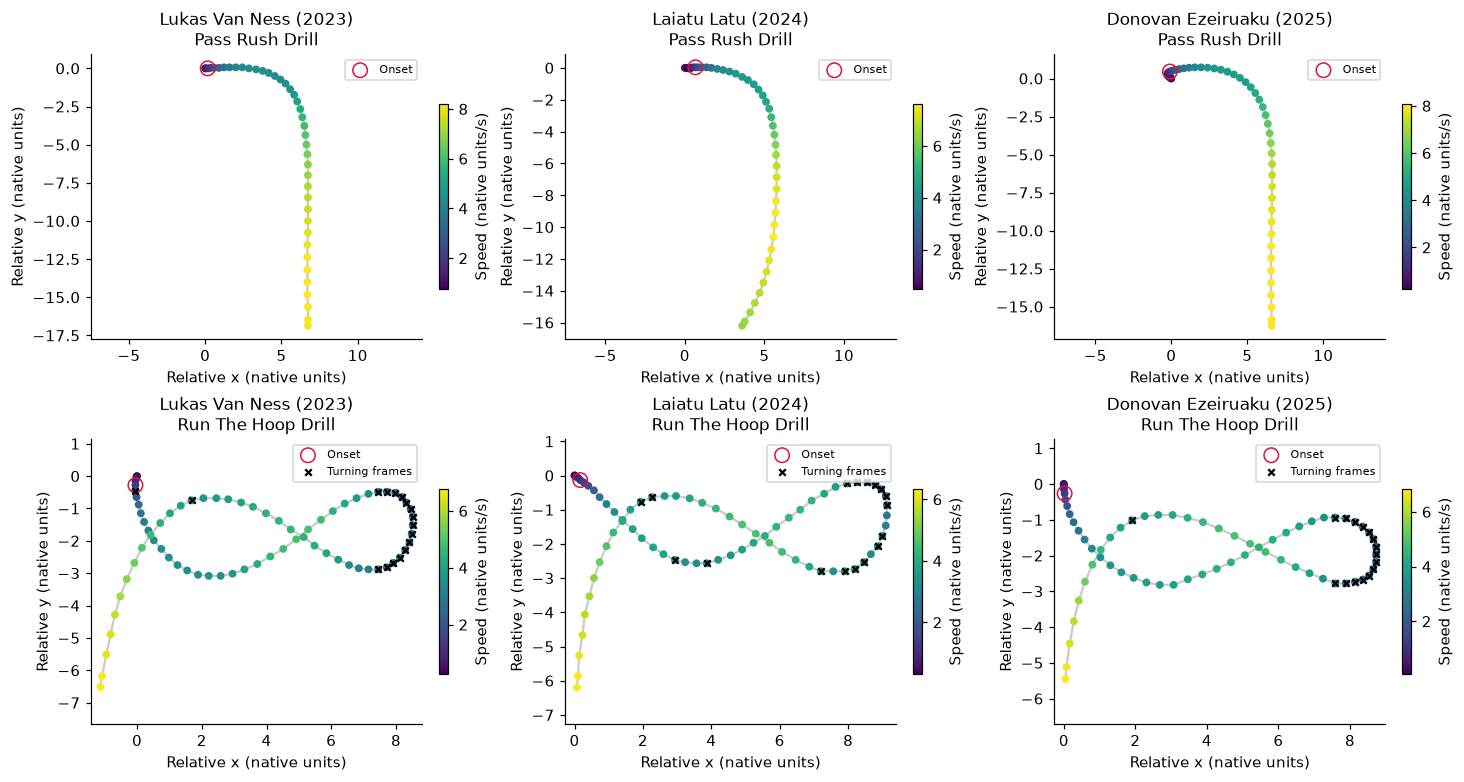

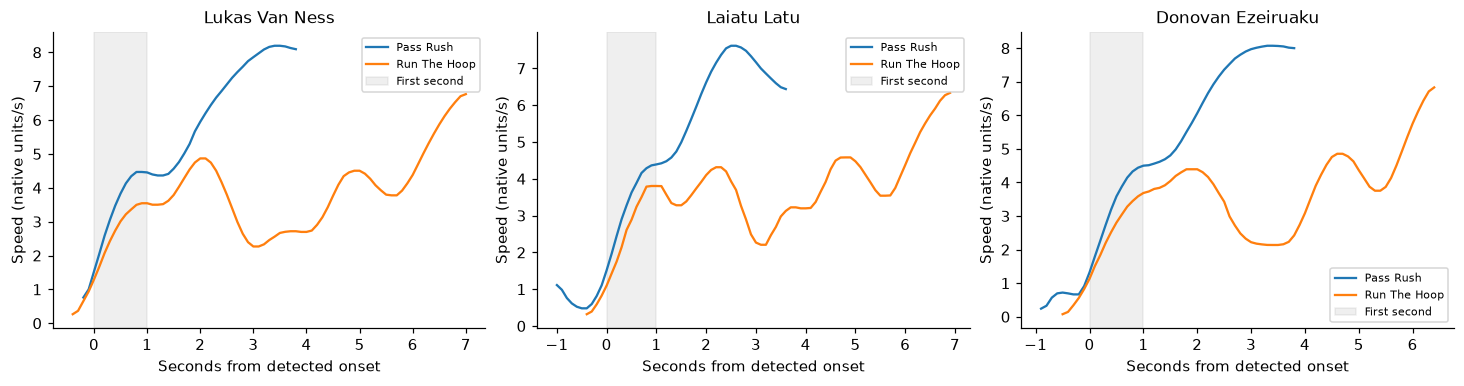

In [6]:
# One player per class, selected without referring to their NFL outcomes.
example_ids = (cohort.loc[cohort.valid_both_drills].sort_values("nfl_id")
               .groupby("draft_year").head(1).nfl_id.tolist())
example_frames = {}
fig, axes = plt.subplots(2, len(example_ids), figsize=(4.4 * len(example_ids), 7), squeeze=False,
                         constrained_layout=True)
for col, nfl_id in enumerate(example_ids):
    person = prospects.set_index("nfl_id").loc[nfl_id]
    for row, drill in enumerate(DRILLS):
        chosen = valid_attempts.loc[valid_attempts.nfl_id.eq(nfl_id) & valid_attempts.drill_name.eq(drill)].iloc[0]
        mask = np.logical_and.reduce([tracking[k].eq(chosen[k]).to_numpy() for k in ATTEMPT_KEY])
        frame = tracking.loc[mask]
        d, _ = prepare_attempt(frame)
        example_frames[(nfl_id, drill)] = (frame, d)
        ax = axes[row, col]
        x, y = d["x"] - d["x"][0], d["y"] - d["y"][0]
        ax.plot(x, y, color="0.8", zorder=0)
        sc = ax.scatter(x, y, c=d["s"], cmap="viridis", s=17)
        start = d["onset"]
        ax.scatter(x[start], y[start], facecolors="none", edgecolors="crimson", s=90, label="Onset")
        if drill == "RUN_THE_HOOP_DRILL":
            turn = d["turning"]
            ax.scatter(x[turn], y[turn], marker="x", c="black", s=18, label="Turning frames")
        ax.set(title=f"{person.display_name} ({person.draft_year})\n{drill.replace('_', ' ').title()}",
               xlabel="Relative x (native units)", ylabel="Relative y (native units)")
        ax.set_aspect("equal", adjustable="datalim")
        ax.legend(fontsize=7, loc="best")
        fig.colorbar(sc, ax=ax, shrink=.65, label="Speed (native units/s)")
plt.show()

fig, axes = plt.subplots(1, len(example_ids), figsize=(4.4 * len(example_ids), 3.4), squeeze=False,
                         constrained_layout=True)
for ax, nfl_id in zip(axes.flat, example_ids):
    for drill in DRILLS:
        _, d = example_frames[(nfl_id, drill)]
        ax.plot(d["t"] - d["t"][d["onset"]], d["s"], label=drill.replace("_DRILL", "").replace("_", " ").title())
    ax.axvspan(0, 1, color="gray", alpha=.12, label="First second")
    ax.set(title=prospects.set_index("nfl_id").loc[nfl_id, "display_name"],
           xlabel="Seconds from detected onset", ylabel="Speed (native units/s)")
    ax.legend(fontsize=7)
plt.show()

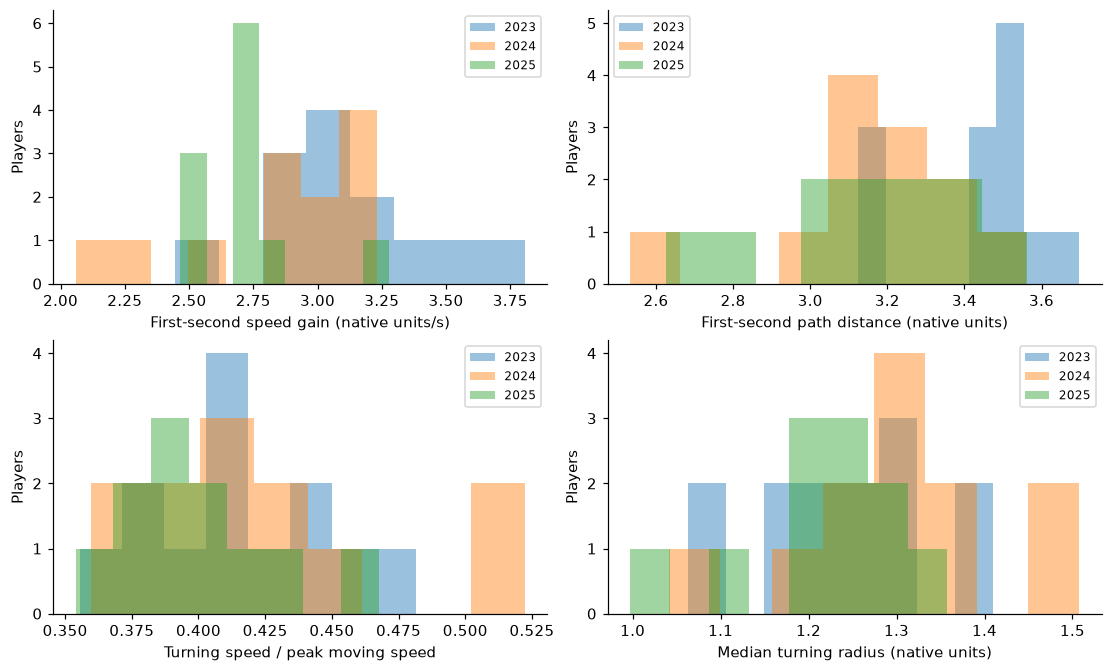

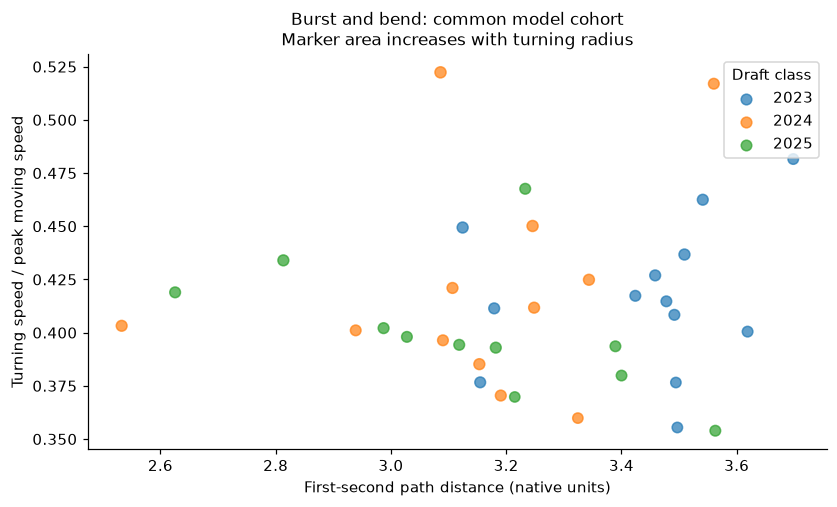

,burst_speed_gain_1s,burst_distance_1s,bend_speed_retention,bend_turn_radius,recorded_pressure_rate,sack_credit_rate
Exploratory Spearman correlations; not held-out evidence,,,,,,
burst_speed_gain_1s,1.00,0.73,0.20,-0.09,-0.16,-0.09
burst_distance_1s,0.73,1.00,0.01,-0.36,0.08,0.08
bend_speed_retention,0.20,0.01,1.00,0.53,-0.20,-0.22
bend_turn_radius,-0.09,-0.36,0.53,1.00,-0.06,-0.18
recorded_pressure_rate,-0.16,0.08,-0.20,-0.06,1.00,0.56
sack_credit_rate,-0.09,0.08,-0.22,-0.18,0.56,1.00


In [7]:
feature_labels = {
    "burst_speed_gain_1s": "First-second speed gain (native units/s)",
    "burst_distance_1s": "First-second path distance (native units)",
    "bend_speed_retention": "Turning speed / peak moving speed",
    "bend_turn_radius": "Median turning radius (native units)",
}
fig, axes = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True)
for ax, feature in zip(axes.flat, MOVEMENT):
    for year, z in analysis.groupby("draft_year"):
        ax.hist(z[feature], bins=8, alpha=.45, label=str(year))
    ax.set(xlabel=feature_labels[feature], ylabel="Players")
    ax.legend(fontsize=8)
plt.show()
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for year, z in analysis.groupby("draft_year"):
    ax.scatter(z.burst_distance_1s, z.bend_speed_retention,
               s=30 + 15 * z.bend_turn_radius, alpha=.7, label=str(year))
ax.set(xlabel=feature_labels["burst_distance_1s"], ylabel=feature_labels["bend_speed_retention"],
       title="Burst and bend: common model cohort\nMarker area increases with turning radius")
ax.legend(title="Draft class")
plt.show()
display(analysis[MOVEMENT + ["recorded_pressure_rate", "sack_credit_rate"]]
        .corr(method="spearman").round(2).rename_axis("Exploratory Spearman correlations; not held-out evidence"))

## 4. Same-player, held-out-class model comparison

**Models:** cohort mean; traditional; traditional + burst; traditional + bend; traditional + both. Traditional includes size, 40, 10-yard split, three-cone, shuttle, vertical, and broad jump. No draft capital, career outcomes, scouting scores, names, or year indicators enter the predictors.

For each held-out draft class, imputation (with missingness indicators) and scaling are fit on **training players only**. Every logistic regression uses fixed `C=1`, L2 regularization, and an unpenalized intercept; no search is performed. Opportunity-level rows receive weight `1 / player_opportunities`, so each training player has total weight one. Preprocessing also uses one row per player. This intentionally targets player-average prediction rather than letting high-volume players dominate. The reference is the training players' mean recorded-pressure rate.

Three-class cross-validation measures cohort transfer, but the 2023 and 2024 folds train partly on later classes. **Only the 2025 fold is forward in time (2023–2024 → 2025).** Because its outputs are visible during this exploration, it is not a sealed final competition test set.

MAE measures player-rate error; Brier measures opportunity-level probabilistic error and is naturally opportunity-weighted. Paired bootstrap intervals resample whole players within draft class, keeping all of a player's opportunities together. They condition on fitted predictions, do not refit models, and are not definitive significance tests. Positive improvement means lower error than Traditional.

In [8]:
MODEL_FEATURES = {
    "Reference": [],
    "Traditional": TRADITIONAL,
    "Traditional + burst": TRADITIONAL + BURST,
    "Traditional + bend": TRADITIONAL + BEND,
    "Traditional + both": TRADITIONAL + MOVEMENT,
}
MODELING_ALLOWED = bool(PROXY_AUDIT_PASSED and SCALE_AUDIT_PASSED)

def run_comparison(player_frame, label):
    records, diagnostics = [], []
    if not MODELING_ALLOWED:
        return pd.DataFrame(), pd.DataFrame([{"scenario": label, "status": "Blocked by audit"}])
    for held_out in sorted(cohort.draft_year.unique()):
        train = player_frame.loc[player_frame.draft_year.ne(held_out)].copy()
        test = player_frame.loc[player_frame.draft_year.eq(held_out)].copy()
        diag = {"scenario": label, "held_out": held_out, "train_players": len(train), "test_players": len(test)}
        if len(train) < 5 or len(test) < 2 or train.draft_year.nunique() < 2:
            diagnostics.append(diag | {"status": "Skipped: <5 train, <2 test, or missing training class"})
            continue
        assert set(train.nfl_id).isdisjoint(test.nfl_id)
        train_opps = opportunities.loc[opportunities.nfl_id.isin(train.nfl_id)].copy()
        y = train_opps.recorded_pressure.to_numpy()
        if len(np.unique(y)) < 2:
            diagnostics.append(diag | {"status": "Skipped: only one training outcome"})
            continue
        train_ids = train.nfl_id.to_numpy()
        lookup = pd.Series(np.arange(len(train)), index=train_ids)
        opp_indices = train_opps.nfl_id.map(lookup).to_numpy(dtype=int)
        weights = 1 / train_opps.groupby("nfl_id").nfl_id.transform("size").to_numpy()
        assert np.allclose(pd.Series(weights).groupby(train_opps.nfl_id.to_numpy()).sum(), 1)
        diagnostics.append(diag | {"status": "OK"})
        for name, columns in MODEL_FEATURES.items():
            if name == "Reference":
                prediction = np.full(len(test), train.recorded_pressure_rate.mean())
            else:
                preprocess = make_pipeline(SimpleImputer(strategy="median", add_indicator=True,
                                                          keep_empty_features=True), StandardScaler())
                X_train = preprocess.fit_transform(train[columns])
                X_test = preprocess.transform(test[columns])
                model = LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000, random_state=SEED)
                model.fit(X_train[opp_indices], y, sample_weight=weights)
                assert model.n_iter_.max() < model.max_iter, "Model failed to converge"
                prediction = model.predict_proba(X_test)[:, 1]
            assert np.isfinite(prediction).all() and ((prediction >= 0) & (prediction <= 1)).all()
            result = test[["nfl_id", "display_name", "draft_year", "opportunities",
                           "recorded_pressures", "recorded_pressure_rate"]].copy()
            result["prediction"] = prediction
            result["model"] = name
            result["scenario"] = label
            records.append(result)
    return (pd.concat(records, ignore_index=True) if records else pd.DataFrame(), pd.DataFrame(diagnostics))

def metrics(frame):
    # Exact opportunity-level Brier from player counts; no independence assumption needed.
    p = frame.prediction.to_numpy()
    k, n = frame.recorded_pressures.to_numpy(), frame.opportunities.to_numpy()
    return {"MAE": np.mean(np.abs(p - k/n)),
            "Brier": np.sum(k * (1-p)**2 + (n-k) * p**2) / n.sum()}

def summarize_predictions(predictions):
    rows = []
    if predictions.empty:
        return pd.DataFrame()
    for model, z in predictions.groupby("model", sort=False):
        for split, part in [("All held-out classes", z), *[(str(y), f) for y, f in z.groupby("draft_year")]]:
            rows.append({"model": model, "split": split, "players": len(part),
                         "opportunities": int(part.opportunities.sum()), **metrics(part)})
    return pd.DataFrame(rows)

predictions, fold_audit = run_comparison(analysis, "Main: 25+ opportunities")
display(fold_audit)
scorecard = summarize_predictions(predictions)
if len(scorecard):
    display(scorecard.round(4))
else:
    display(Markdown("**No model results:** inspect the audit and cohort counts above."))

,scenario,held_out,train_players,test_players,status
0,Main: 25+ opportunities,2023,23,13,OK
1,Main: 25+ opportunities,2024,24,12,OK
2,Main: 25+ opportunities,2025,25,11,OK


,model,split,players,opportunities,MAE,Brier
0,Reference,All held-out classes,36,5107,0.0298,0.0930
1,Reference,2023,13,1893,0.0261,0.0934
2,Reference,2024,12,1688,0.0401,0.1019
3,Reference,2025,11,1526,0.0229,0.0828
4,Traditional,All held-out classes,36,5107,0.0349,0.0932
5,Traditional,2023,13,1893,0.0267,0.0930
6,Traditional,2024,12,1688,0.0485,0.1025
7,Traditional,2025,11,1526,0.0299,0.0832
8,Traditional + burst,All held-out classes,36,5107,0.0346,0.0933
9,Traditional + burst,2023,13,1893,0.0260,0.0930


,split,model,metric,improvement_vs_traditional,ci_low,ci_high,players
0,All held-out classes,Reference,MAE,0.0052,0.0004,0.0103,36
1,All held-out classes,Reference,Brier,0.0002,-0.0003,0.0006,36
2,All held-out classes,Traditional + burst,MAE,0.0003,-0.0018,0.0026,36
3,All held-out classes,Traditional + burst,Brier,-0.0001,-0.0002,0.0001,36
4,All held-out classes,Traditional + bend,MAE,-0.0005,-0.0016,0.0006,36
5,All held-out classes,Traditional + bend,Brier,-0.0001,-0.0002,0.0000,36
6,All held-out classes,Traditional + both,MAE,0.0002,-0.0019,0.0025,36
7,All held-out classes,Traditional + both,Brier,-0.0001,-0.0003,0.0001,36
8,2025 forward in time,Reference,MAE,0.0071,0.0023,0.0115,11
9,2025 forward in time,Reference,Brier,0.0004,0.0001,0.0006,11


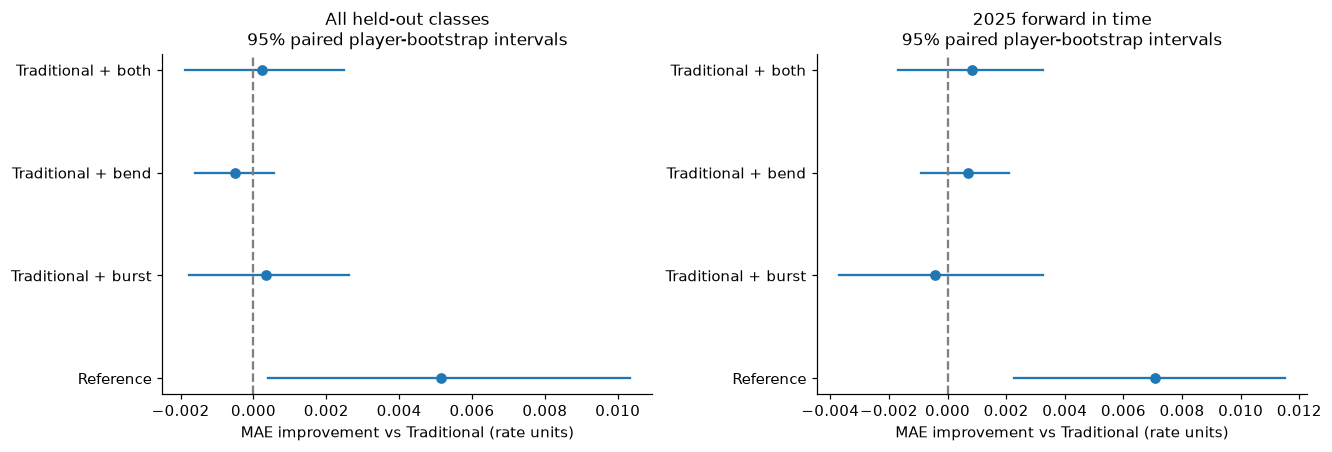

In [9]:
def paired_bootstrap(predictions, repetitions=BOOTSTRAPS):
    if predictions.empty:
        return pd.DataFrame()
    wide = predictions.pivot(index=["nfl_id", "draft_year", "opportunities", "recorded_pressures"],
                             columns="model", values="prediction").reset_index()
    assert wide[list(MODEL_FEATURES)].notna().all().all(), "Models must predict identical players"
    rows = []
    scopes = [("All held-out classes", wide)]
    if wide.draft_year.eq(2025).any():
        scopes.append(("2025 forward in time", wide.loc[wide.draft_year.eq(2025)]))
    for split, z in scopes:
        z = z.reset_index(drop=True)
        rng = np.random.default_rng(SEED)
        strata = [np.flatnonzero(z.draft_year.to_numpy() == year) for year in sorted(z.draft_year.unique())]
        bootstrap_indices = np.stack([np.concatenate([rng.choice(ids, len(ids), replace=True)
                                                      for ids in strata]) for _ in range(repetitions)])
        n, k = z.opportunities.to_numpy(), z.recorded_pressures.to_numpy()
        observed = k / n
        baseline = z["Traditional"].to_numpy()
        base_mae = np.abs(baseline - observed)
        base_brier_sum = k * (1-baseline)**2 + (n-k) * baseline**2
        for name in MODEL_FEATURES:
            if name == "Traditional":
                continue
            p = z[name].to_numpy()
            mae_gain = base_mae - np.abs(p-observed)
            brier_gain_sum = base_brier_sum - (k*(1-p)**2 + (n-k)*p**2)
            draws = {
                "MAE": mae_gain[bootstrap_indices].mean(axis=1),
                "Brier": brier_gain_sum[bootstrap_indices].sum(axis=1) / n[bootstrap_indices].sum(axis=1),
            }
            point = {"MAE": mae_gain.mean(), "Brier": brier_gain_sum.sum()/n.sum()}
            for metric, samples in draws.items():
                low, high = np.quantile(samples, [.025, .975])
                rows.append({"split": split, "model": name, "metric": metric,
                             "improvement_vs_traditional": point[metric], "ci_low": low, "ci_high": high,
                             "players": len(z)})
    return pd.DataFrame(rows)

improvements = paired_bootstrap(predictions)
if len(improvements):
    display(improvements.round(4))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for ax, split in zip(axes, ["All held-out classes", "2025 forward in time"]):
        z = improvements.loc[improvements.split.eq(split) & improvements.metric.eq("MAE")]
        for i, row in enumerate(z.itertuples()):
            ax.plot([row.ci_low, row.ci_high], [i, i], color="tab:blue")
            ax.scatter(row.improvement_vs_traditional, i, color="tab:blue")
        ax.axvline(0, color="gray", linestyle="--")
        ax.set(yticks=range(len(z)), yticklabels=z.model, xlabel="MAE improvement vs Traditional (rate units)",
               title=f"{split}\n95% paired player-bootstrap intervals")
    plt.show()

## 5. Sensitivity and secondary outcomes

Repeat the entire same-player comparison at 50 opportunities and on players with all eight traditional inputs observed. Also show a complete-40-and-three-cone subset: the other traditional tests remain imputed within training folds. These are different populations, so changes across scenarios cannot be attributed to modeling alone. Unsupported folds are explicitly skipped rather than filled with in-sample estimates.

Sack credits (including half sacks) and recorded quick pressures are descriptive secondary outcomes. The pressure target does not use these to fabricate missing labels. Unblocked pressures remain in the main target; their proportion is displayed to make the role of free paths visible.

In [10]:
scenarios = {
    "50+ opportunities": analysis.loc[analysis.opportunities.ge(50)],
    "All traditional inputs observed": analysis.dropna(subset=TRADITIONAL),
    "40 and three-cone observed": analysis.dropna(subset=["forty", "three_cone"]),
}
sensitivity_predictions = []
sensitivity_audits = []
sensitivity_scores = []
for label, subset in scenarios.items():
    pred, audit_frame = run_comparison(subset, label)
    sensitivity_audits.append(audit_frame)
    if len(pred):
        sensitivity_predictions.append(pred)
        sensitivity_scores.append(summarize_predictions(pred).assign(scenario=label))
display(pd.DataFrame({name: frame.groupby("draft_year").size() for name, frame in scenarios.items()}).fillna(0).astype(int))
display(pd.concat(sensitivity_audits, ignore_index=True))
if sensitivity_scores:
    display(pd.concat(sensitivity_scores, ignore_index=True).round(4))

def secondary_summary(z):
    n = z.opportunities.sum()
    return pd.Series({"players": len(z), "opportunities": n,
                      "recorded_pressure_rate": z.recorded_pressures.sum()/n,
                      "sack_credits_per_opportunity": z.sack_credits.sum()/n,
                      "recorded_quick_pressures_per_opportunity": z.recorded_quick_pressures.sum()/n,
                      "unblocked_fraction_of_recorded_pressures":
                          z.recorded_unblocked_pressures.sum()/max(z.recorded_pressures.sum(), 1)})
if len(analysis):
    display(pd.DataFrame({year: secondary_summary(z) for year, z in analysis.groupby("draft_year")}).T.round(4))

,50+ opportunities,All traditional inputs observed,40 and three-cone observed
draft_year,,,
2023,9,3,5
2024,11,3,3
2025,8,3,3


,scenario,held_out,train_players,test_players,status
0,50+ opportunities,2023,19,9,OK
1,50+ opportunities,2024,17,11,OK
2,50+ opportunities,2025,20,8,OK
3,All traditional inputs observed,2023,6,3,OK
4,All traditional inputs observed,2024,6,3,OK
5,All traditional inputs observed,2025,6,3,OK
6,40 and three-cone observed,2023,6,5,OK
7,40 and three-cone observed,2024,8,3,OK
8,40 and three-cone observed,2025,8,3,OK


,model,split,players,opportunities,MAE,Brier,scenario
0,Reference,All held-out classes,28,4815,0.0297,0.0942,50+ opportunities
1,Reference,2023,9,1767,0.0236,0.0953,50+ opportunities
2,Reference,2024,11,1644,0.0435,0.1016,50+ opportunities
3,Reference,2025,8,1404,0.0176,0.0841,50+ opportunities
4,Traditional,All held-out classes,28,4815,0.0367,0.0944,50+ opportunities
5,Traditional,2023,9,1767,0.0268,0.0950,50+ opportunities
6,Traditional,2024,11,1644,0.0496,0.1023,50+ opportunities
7,Traditional,2025,8,1404,0.0301,0.0846,50+ opportunities
8,Traditional + burst,All held-out classes,28,4815,0.0372,0.0945,50+ opportunities
9,Traditional + burst,2023,9,1767,0.0271,0.0951,50+ opportunities


,players,opportunities,recorded_pressure_rate,sack_credits_per_opportunity,recorded_quick_pressures_per_opportunity,unblocked_fraction_of_recorded_pressures
2023,13.0,1893.0,0.1041,0.0151,0.0349,0.1574
2024,12.0,1688.0,0.1143,0.0101,0.0379,0.1140
2025,11.0,1526.0,0.0911,0.0082,0.0275,0.1655


## 6. Validation and interpretation

These checks cover outcome bounds, equal player weighting, shared evaluation cohorts, chronological separation for the forward fold, and measurement behavior. Synthetic tracks check distance extraction, curvature radius, rotation/translation invariance, and rejection of tracking gaps. They do not establish that the physiological interpretation is correct.

In [11]:
# Synthetic movement: stationary lead-in, then constant-speed straight motion.
t = np.arange(61) / 10
elapsed = np.maximum(t - 1.0, 0)
synthetic = pd.DataFrame({"time": pd.Timestamp("2025-01-01") + pd.to_timedelta(t, unit="s"),
                          "x": 2*elapsed, "y": np.zeros_like(t),
                          "s": np.where(t > 1, 2., 0.), "drill_name": "PASS_RUSH_DRILL"})
v, status = extract_attempt(synthetic)
assert status == "ok" and np.isclose(v["burst_distance_1s"], 2, atol=.03)
assert np.isclose(v["burst_speed_gain_1s"], 0, atol=.03)
# A constant-speed circle should retain speed and recover its known radius.
radius = 3.
angle = 2 * elapsed / radius
circle = synthetic.copy()
circle["x"], circle["y"] = radius*np.cos(angle), radius*np.sin(angle)
circle["drill_name"] = "RUN_THE_HOOP_DRILL"
v, status = extract_attempt(circle)
assert status == "ok" and np.isclose(v["bend_speed_retention"], 1)
assert np.isclose(v["bend_turn_radius"], radius, rtol=.08)
# 90-degree rotation + translation is exactly compatible with coordinate-wise median smoothing.
rotated = circle.copy()
rotated["x"], rotated["y"] = -circle.y + 100, circle.x - 20
vr, sr = extract_attempt(rotated)
assert sr == "ok" and np.isclose(vr["bend_turn_radius"], v["bend_turn_radius"], rtol=.01)
gapped = synthetic.drop(index=20)
assert extract_attempt(gapped)[1] == "timestamp_gap"
assert not analysis.nfl_id.duplicated().any()
assert np.isfinite(analysis[MOVEMENT].to_numpy()).all()
if len(predictions):
    assert not predictions.duplicated(["model", "nfl_id"]).any()
    expected_ids = set(predictions.loc[predictions.model.eq("Reference"), "nfl_id"])
    for name in MODEL_FEATURES:
        assert set(predictions.loc[predictions.model.eq(name), "nfl_id"]) == expected_ids
    forward_training = analysis.loc[analysis.draft_year.ne(2025)]
    assert forward_training.draft_year.lt(2025).all()
    # Count-based Brier is exactly the Brier calculated from individual opportunities.
    test_preds = predictions.loc[predictions.model.eq("Traditional")]
    expanded = opportunities.merge(test_preds[["nfl_id", "prediction"]], on="nfl_id", validate="many_to_one")
    assert np.isclose(metrics(test_preds)["Brier"],
                      np.mean((expanded.prediction - expanded.recorded_pressure)**2))
print("Validation passed: joins, labels, movement features, model cohorts, and scoring checks.")

Validation passed: joins, labels, movement features, model cohorts, and scoring checks.


In [12]:
if len(improvements):
    lines = [f"**Current evidence:** the main comparison contains {len(analysis)} players "
             f"and {int(analysis.opportunities.sum()):,} eligible opportunity proxies."]
    for split in ["All held-out classes", "2025 forward in time"]:
        z = improvements.loc[improvements.split.eq(split) & improvements.metric.eq("MAE") &
                             improvements.model.eq("Traditional + both")]
        if len(z):
            row = z.iloc[0]
            change = row.improvement_vs_traditional * 100
            direction = "lower" if change >= 0 else "higher"
            lines.append(f"- **{split}:** adding both movement families produced {abs(change):.2f} "
                         f"percentage points {direction} player MAE than Traditional "
                         f"(paired improvement interval {row.ci_low*100:.2f} to {row.ci_high*100:.2f} points).")
    overall = scorecard.loc[scorecard.split.eq("All held-out classes")].set_index("model")
    reference_mae = overall.loc["Reference", "MAE"]
    combined_mae = overall.loc["Traditional + both", "MAE"]
    comparison = "lower" if reference_mae < combined_mae else "higher"
    lines.append(f"**Check the simple baseline:** the training-cohort mean has {comparison} pooled MAE "
                 f"than Traditional + both ({reference_mae*100:.2f} vs {combined_mae*100:.2f} percentage points). "
                 "Small gains over Traditional alone are insufficient if a simple mean predicts better.")
    lines.append("These are exploratory recorded-label results. An interval spanning zero does not establish "
                 "an improvement; even a positive interval does not independently validate pressure semantics or "
                 "show that the movement trait causes better pass rushing.")
    display(Markdown("\n\n".join(lines)))
else:
    display(Markdown("**No predictive conclusion is available.** Resolve the audit or sample-size limits above."))
if not TRUE_PRESSURE_CONCLUSIONS_ALLOWED:
    display(Markdown("**True pressure-rate conclusions remain blocked:** obtain the official label definitions "
                     "and validate the opportunity proxy before describing these predictions as pass-rush success."))

**Current evidence:** the main comparison contains 36 players and 5,107 eligible opportunity proxies.

- **All held-out classes:** adding both movement families produced 0.02 percentage points lower player MAE than Traditional (paired improvement interval -0.19 to 0.25 points).

- **2025 forward in time:** adding both movement families produced 0.08 percentage points lower player MAE than Traditional (paired improvement interval -0.17 to 0.33 points).

**Check the simple baseline:** the training-cohort mean has lower pooled MAE than Traditional + both (2.98 vs 3.47 percentage points). Small gains over Traditional alone are insufficient if a simple mean predicts better.

These are exploratory recorded-label results. An interval spanning zero does not establish an improvement; even a positive interval does not independently validate pressure semantics or show that the movement trait causes better pass rushing.

**True pressure-rate conclusions remain blocked:** obtain the official label definitions and validate the opportunity proxy before describing these predictions as pass-rush success.

### What to investigate next

- Verify pass-rush opportunities and missing pressure semantics against the official competition dictionary or organizer clarification. The consistency audit supports only the explicitly defined proxy.
- Review onset and turning segments across players and drill years before optimizing features. Attempt counts are uneven, and some single-attempt measurements cannot be checked for repeatability.
- Investigate deployment, blocking, unblocked paths, injuries, opponent quality, and playing-time selection using NFL game tracking. None is controlled in this first comparison.
- Audit sensitivity to movement thresholds and regularization without repeatedly selecting choices against the visible 2025 results. The small player sample and multiple feature comparisons make apparent gains fragile.
- If a signal survives validation, use burst–bend profiles to guide film review and propose development hypotheses. Do not use this notebook alone to rank draft prospects or infer that training a metric will improve NFL performance.

**Selection limit:** this is conditional on inclusion in the supplied data, participation in both drills, and at least 25 observed eligible rookie opportunities. It cannot predict whether an unobserved prospect earns playing time, and low/no-opportunity players are not labeled busts.